In [15]:
from lib_linear_probing import *
from deep_models.vae_train import *
from deep_models.vae import *
import torch
from deep_models.data import S00MILDataset, make_splits, load_folds
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import torch 
import pandas as pd
from sklearn.manifold import TSNE

In [16]:
dev_path = "/dmj/fizmed/mmarzec/licencjat_neuro/DL-NS/split_data/one_site/splits/s00_developmental.npz"
split_k = 7
num_workers = 2

In [17]:
developamental_folds = load_folds(dev_path)
_, train_idx, val_idx, test_idx = next(split for split in make_splits(developamental_folds) if split[0] == split_k)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")

train=1085  val=132  test=136


In [18]:
trainset = S00MILDataset(train_idx, max_instances=150, train=True)
valset = S00MILDataset(val_idx, max_instances=150, train=False)
testset = S00MILDataset(test_idx, max_instances=150, train=False)


loader_kw = dict(batch_size=10, num_workers=num_workers, pin_memory=True) # type: ignore
trainloader = DataLoader(trainset, shuffle=True, **loader_kw)  # type: ignore
valloader = DataLoader(valset, shuffle=False, **loader_kw) # type: ignore
testloader = DataLoader(testset, shuffle=False, **loader_kw) # type: ignore

In [19]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LATENT_DIM = 64

In [20]:
raw_tr, y_train = extract_raw_from_loader(trainloader)
raw_va, y_val   = extract_raw_from_loader(valloader)
raw_te, y_test  = extract_raw_from_loader(testloader)

raw_splits = {"train": raw_tr, "val": raw_va, "test": raw_te}

### 1. Baseline: Flattened off-diagonal raw inputs (5 * 17 * 16 = 1360 dims)


In [21]:
bags = {"raw_offdiag": {s: flatten_offdiag_bags(raw_splits[s]) for s in ("train", "val", "test")}}

### 2. Baseline: PCA on flattened off-diagonal raw inputs (64 dims, matching VAE latent_dim)

In [22]:
bags["pca"] = pca_bags(bags["raw_offdiag"], n_components=LATENT_DIM, seed=0)

### 3. Random ConvVAE (initialized with init_model, NO training)

In [24]:
torch.manual_seed(0)
vae_rand = SparseConvVAE(latent=LATENT_DIM, alpha=0.1).to(device)
init_model(vae_rand, trainloader)  # Same Xavier/He init as before training
vae_rand.eval()
bags["vae_random_mu"] = {s: embed_raw_bags(vae_rand, raw_splits[s], device=device) for s in ("train", "val", "test")} #type:ignore

### 4. Trained ConvVAE

In [26]:
path = f"best_svae_fold{split_k}.pt"
vae_trained = SparseConvVAE(latent=LATENT_DIM, alpha=0.1).to(device)
state_dict = torch.load(path, map_location=device, weights_only=True)
vae_trained.load_state_dict(state_dict)
vae_trained.eval()

bags["vae_trained_mu"] = {s: embed_raw_bags(vae_trained, raw_splits[s], device=device) for s in ("train", "val", "test")} #type:ignore

### 5. Trained VAE - active dimensions (threshold for mu_variance 0.1)

In [27]:
mask = active_mask(bags["vae_trained_mu"]["train"], thr=0.1)
print(f"Trained VAE active units: {mask.sum()} / {LATENT_DIM}")
bags["vae_trained_mu_active"] = select_dims(bags["vae_trained_mu"], mask)

Trained VAE active units: 37 / 64


In [28]:
representations = ["raw_offdiag", "pca", "vae_random_mu", "vae_trained_mu", "vae_trained_mu_active"]

In [29]:
rows, artifacts = run_nn_probes(bags=bags,
                                representations=representations,
                                y_train=y_train,
                                y_val=y_val,
                                y_test=y_test,
                                return_artifacts=True,
                                abmil_variants={"ABMIL_linear": None, "ABMIL_h64": 64})
df = pd.DataFrame(rows)

[raw_offdiag] LinearBagProbe  val AUC = 0.697  epoch = 79  test AUC = 0.772
[raw_offdiag] LinearInstanceProbeBagLabels_soft  val AUC = 0.703  epoch = 20  test AUC = 0.756
[raw_offdiag] LinearInstanceProbeBagLabels_vote  val AUC = 0.708  epoch = 20  test AUC = 0.745
[raw_offdiag] ABMIL_linear  val AUC = 0.675  epoch = 15  test AUC = 0.667
[raw_offdiag] ABMIL_h64  val AUC = 0.698  epoch = 21  test AUC = 0.728
[pca] LinearBagProbe  val AUC = 0.675  epoch = 14  test AUC = 0.711
[pca] LinearInstanceProbeBagLabels_soft  val AUC = 0.706  epoch = 50  test AUC = 0.724
[pca] LinearInstanceProbeBagLabels_vote  val AUC = 0.714  epoch = 50  test AUC = 0.736
[pca] ABMIL_linear  val AUC = 0.726  epoch = 10  test AUC = 0.720
[pca] ABMIL_h64  val AUC = 0.739  epoch = 14  test AUC = 0.675
[vae_random_mu] LinearBagProbe  val AUC = 0.591  epoch = 4  test AUC = 0.621
[vae_random_mu] LinearInstanceProbeBagLabels_soft  val AUC = 0.574  epoch = 26  test AUC = 0.692
[vae_random_mu] LinearInstanceProbeBagLabels

## Visualization in 2-dims

In [30]:
embeddings_2d = {rep: TSNE(n_components=2, init="pca", learning_rate="auto", random_state=0).fit_transform(artifacts[rep]["X_val"]) for rep in representations}

In [31]:
val_sizes = np.array([len(b) for b in bags["vae_trained_mu"]["val"]])
exam_ids = np.repeat(np.arange(len(val_sizes)), val_sizes)
window_labels = np.repeat(y_val, val_sizes)

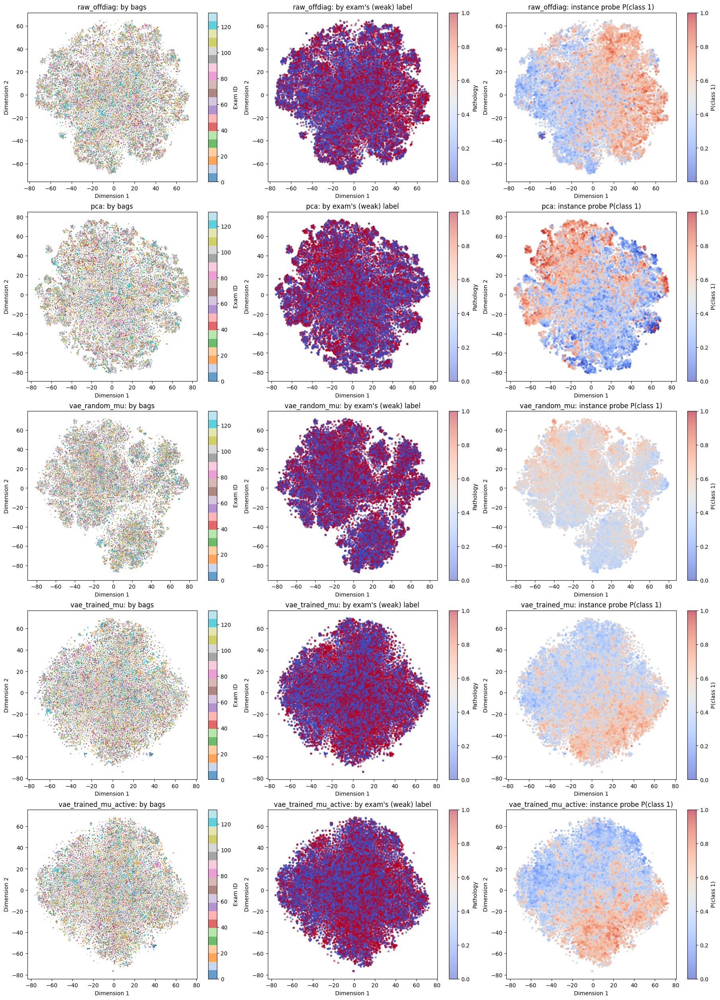

In [32]:
fig, axes = plot_embedding_votes(embeddings=embeddings_2d,
                                 artifacts=artifacts,
                                 exam_ids=exam_ids,
                                 window_labels=window_labels,
                                 rep_of=representations,
                                 mode="prob")
plt.show()

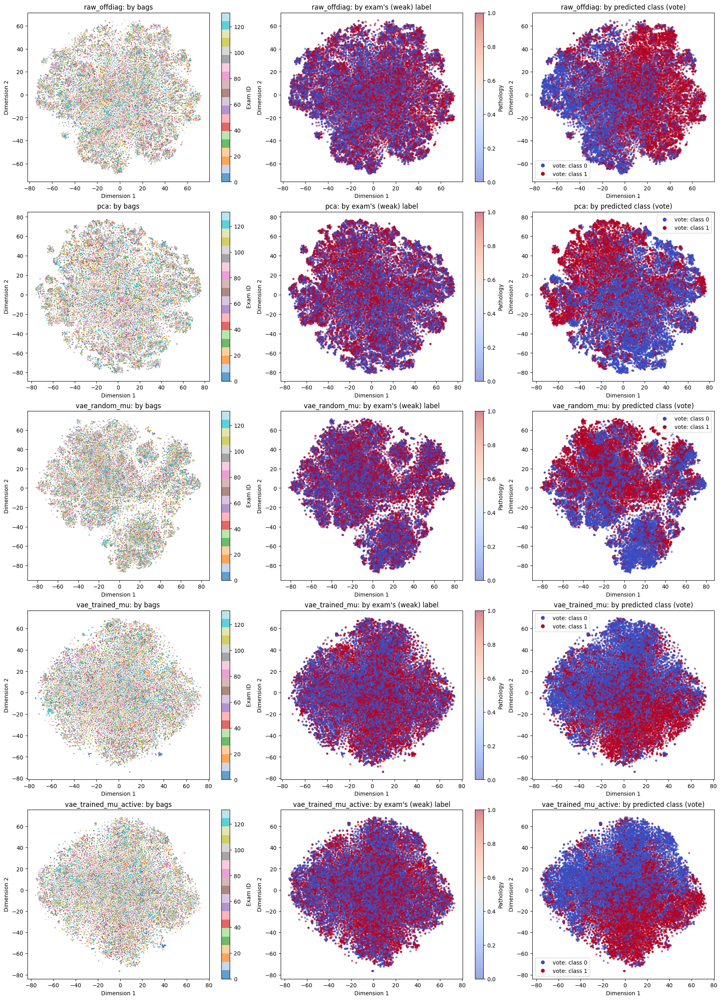

In [33]:
fig, axes = plot_embedding_votes(embeddings=embeddings_2d,
                                 artifacts=artifacts,
                                 exam_ids=exam_ids,
                                 window_labels=window_labels,
                                 rep_of=representations,
                                 mode="vote")
plt.show()